# Financial news and stock data EDA

We want to test whether news headlines improve next-day stock direction predictions beyond historical market data.

The first two plots use Carmen's saved Alpaca summaries. The other seven use Yahoo prices and EODHD news collected by Joyce. The original Alpaca files are still needed for raw-data checks.

All code and nine saved plots are below. To download the data, follow [data/README.md](../data/README.md).


In [1]:
from pathlib import Path
import os
import json
import re

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "collect_data.ipynb").is_file())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_market_calendars as mcal
from IPython.display import display
%matplotlib inline

COLORS = {"AAPL": "#2367a4", "JNJ": "#c87525", "SPY": "#687582", "AMZN": "#338575"}
figures = ROOT / "figures"
figures.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})

def save(fig, name):
    fig.savefig(figures / f"eda_supplemental_{name}.png", dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)

def _saved_text(cells: list[dict], source_fragment: str) -> str:
    matches = [c for c in cells if source_fragment in "".join(c.get("source", []))]
    if len(matches) != 1:
        raise ValueError(f"Expected one source cell containing {source_fragment!r}")
    texts = [
        "".join(o.get("data", {}).get("text/plain", []))
        for o in matches[0].get("outputs", [])
        if "text/plain" in o.get("data", {})
    ]
    if len(texts) != 1:
        raise ValueError("The collection notebook does not contain the expected saved table.")
    return texts[0]

def read_saved_summaries(project_root: str | Path) -> dict:
    root = Path(project_root)
    notebook = root / "src" / "collect_data.ipynb"
    cells = json.loads(notebook.read_text())["cells"]

    total_text = _saved_text(cells, 'news_all.groupby("ticker").size()')
    totals = {
        ticker: int(count)
        for ticker, count in re.findall(r"^(\w+)\s+(\d+)\s*$", total_text, re.M)
    }
    if not totals:
        raise ValueError("No ticker counts found in the saved output.")

    annual_text = _saved_text(cells, 'groupby(["ticker", "year"])')
    lines = annual_text.splitlines()
    years = [int(y) for y in re.findall(r"\b20\d{2}\b", lines[0])]
    annual_rows = []
    for line in lines[1:]:
        parts = line.split()
        if parts and parts[0] in totals:
            if len(parts) != len(years) + 1:
                raise ValueError("Saved year table has an unexpected shape.")
            annual_rows.extend(
                {"ticker": parts[0], "year": year, "news_records": int(count)}
                for year, count in zip(years, parts[1:])
            )
    annual = pd.DataFrame(annual_rows)
    if annual.groupby("ticker")["news_records"].sum().to_dict() != totals:
        raise ValueError("Annual totals do not match the saved overall counts.")

    price_text = _saved_text(cells, 'prices.groupby("symbol")["timestamp"]')
    coverage_rows = []
    for line in price_text.splitlines():
        parts = line.split()
        if len(parts) == 6 and parts[0] in [*totals, "SPY"]:
            coverage_rows.append(
                {
                    "symbol": parts[0],
                    "first_saved_timestamp_utc": " ".join(parts[1:3]),
                    "last_saved_timestamp_utc": " ".join(parts[3:5]),
                    "price_rows": int(parts[5]),
                }
            )
    coverage = pd.DataFrame(coverage_rows)
    if coverage.empty:
        raise ValueError("No saved price coverage rows found.")

    counts = pd.Series(totals, name="news_records").sort_index().to_frame()
    counts["share_pct"] = counts["news_records"] / counts["news_records"].sum() * 100
    return {"totals": counts, "annual": annual, "price_coverage": coverage}

def prepare_prices(prices, start, end):
    """Reindex to actual sessions before returns/labels; never fill missing prices."""
    required = {"symbol", "date", "open", "high", "low", "close", "volume", "adjusted_close"}
    if missing := required - set(prices):
        raise ValueError(f"Price columns missing: {sorted(missing)}")
    frame = prices.copy()
    frame["date"] = pd.to_datetime(frame["date"]).dt.tz_localize(None).dt.normalize()
    frame = frame.loc[frame.date.ge(pd.Timestamp(start)) & frame.date.lt(pd.Timestamp(end))]
    if frame.empty:
        raise ValueError("No prices in the requested EDA window.")
    calendar = mcal.get_calendar("NYSE")
    schedule = calendar.schedule(start_date=start, end_date=pd.Timestamp(end) - pd.Timedelta(days=1))
    schedule.index = pd.DatetimeIndex(schedule.index).tz_localize(None).normalize()
    rows, checks = [], []
    for symbol, group in frame.groupby("symbol", sort=True):
        duplicate = group.duplicated("date", keep=False)
        numeric = group[["open", "high", "low", "close", "adjusted_close", "volume"]].apply(pd.to_numeric, errors="coerce")
        valid_numeric = np.isfinite(numeric).all(axis=1) & numeric[["open", "high", "low", "close", "adjusted_close"]].gt(0).all(axis=1) & numeric.volume.ge(0)
        valid_ohlc = (numeric.high.ge(numeric[["open", "close", "low"]].max(axis=1)) &
                      numeric.low.le(numeric[["open", "close", "high"]].min(axis=1)))
        valid = ~duplicate & valid_numeric & valid_ohlc & group.date.isin(schedule.index)
        checks.append({"symbol": symbol, "rows": len(group), "duplicate_date_rows": int(duplicate.sum()),
                       "invalid_numeric_rows": int((~valid_numeric).sum()), "invalid_ohlc_rows": int((~valid_ohlc).sum()),
                       "non_session_rows": int((~group.date.isin(schedule.index)).sum()),
                       "expected_sessions": len(schedule), "usable_sessions": int(valid.sum()),
                       "missing_or_excluded_sessions": len(schedule) - int(valid.sum()),
                       "first_observed_date": group.date.min().date().isoformat(),
                       "last_observed_date": group.date.max().date().isoformat()})
        clean = group.loc[valid].copy()
        clean[numeric.columns] = numeric.loc[valid]
        clean = clean.set_index("date").reindex(schedule.index)
        clean.index.name = "date"
        clean["symbol"] = symbol
        clean["return_pct"] = clean.adjusted_close.pct_change(fill_method=None) * 100
        clean["next_return_pct"] = clean.return_pct.shift(-1)
        clean["target_up"] = clean.next_return_pct.gt(0).astype("Int64").where(clean.next_return_pct.notna())
        rows.append(clean.reset_index())
    return pd.concat(rows, ignore_index=True), pd.DataFrame(checks), schedule

def align_news(news, schedule):
    """Assign provider timestamps to the first actual NYSE close at/after them."""
    frame = news.copy()
    if "created_at" not in frame and "date" in frame:
        frame["created_at"] = frame["date"]
    required = {"ticker", "created_at", "headline", "link"}
    if missing := required - set(frame):
        raise ValueError(f"News columns missing: {sorted(missing)}")
    frame["created_at"] = pd.to_datetime(frame.created_at, utc=True, errors="coerce", format="mixed")
    frame["midnight_utc_timestamp"] = (frame.created_at.notna() & frame.created_at.dt.hour.eq(0)
                                        & frame.created_at.dt.minute.eq(0) & frame.created_at.dt.second.eq(0)
                                        & frame.created_at.dt.microsecond.eq(0))
    frame["headline"] = frame.headline.astype("string")
    frame["blank_headline"] = frame.headline.isna() | frame.headline.str.strip().eq("").fillna(True)
    frame["blank_link"] = frame.link.isna() | frame.link.astype("string").str.strip().eq("").fillna(True)
    frame["duplicate_exact_record"] = frame.duplicated(["ticker", "created_at", "headline", "link"], keep=False)
    complete_key = frame.created_at.notna() & ~frame.blank_headline & ~frame.blank_link & frame.ticker.notna()
    frame["exclude_duplicate_copy"] = complete_key & frame.duplicated(["ticker", "created_at", "headline", "link"], keep="first")
    normalized_title = frame.headline.str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
    link_counts = frame.assign(_title_key=normalized_title).groupby(
        ["ticker", "created_at", "_title_key"], dropna=False)["link"].transform("nunique")
    frame["same_headline_time_across_links"] = frame.created_at.notna() & ~frame.blank_headline & link_counts.gt(1)
    frame["cutoff_date"] = pd.NaT
    valid_times = frame.created_at.notna()
    closes = pd.DatetimeIndex(schedule.market_close)
    positions = closes.searchsorted(pd.DatetimeIndex(frame.loc[valid_times, "created_at"]), side="left")
    eligible_indices = frame.index[valid_times][positions < len(closes)]
    frame.loc[eligible_indices, "cutoff_date"] = schedule.index[positions[positions < len(closes)]]
    # Company aliases are an audit flag, not a claim that all other news is irrelevant.
    aliases = {"AAPL": r"\b(?:apple|aapl)\b", "AMZN": r"\b(?:amazon|amzn|aws)\b"}
    frame["company_named_in_headline"] = False
    for ticker, pattern in aliases.items():
        selected = frame.ticker.eq(ticker)
        frame.loc[selected, "company_named_in_headline"] = frame.loc[selected, "headline"].str.contains(pattern, case=False, regex=True, na=False)
    return frame

saved = read_saved_summaries(ROOT)
saved["metrics"] = {"total_ticker_news_records": int(saved["totals"]["news_records"].sum())}
tables = saved

# These local tables were collected separately from the original Alpaca data.
price_file = ROOT / "data/supplemental/yahoo_prices/prices.parquet"
news_file = ROOT / "data/supplemental/eodhd_news/news.parquet"
missing = [str(p.relative_to(ROOT)) for p in (price_file, news_file) if not p.is_file()]
if missing:
    raise FileNotFoundError("To rerun the EDA, collect or copy these local files first: " + ", ".join(missing))
prices_raw = pd.read_parquet(price_file)
news_raw = pd.read_parquet(news_file)
daily, price_quality, schedule = prepare_prices(prices_raw, "2020-01-01", "2026-10-16")
aligned = align_news(news_raw, schedule)

def schema(frame):
    return [{"column": c, "dtype": str(frame[c].dtype), "missing_rows": int(frame[c].isna().sum())}
            for c in frame]

return_summary=[]
for symbol, group in daily.groupby("symbol"):
    values=group.return_pct.dropna()
    return_summary.append({"symbol":symbol, "return_observations":len(values),
        "mean_daily_return_pct":values.mean(), "daily_return_std_pct":values.std(),
        "min_daily_return_pct":values.min(), "max_daily_return_pct":values.max(),
        "up_day_pct":values.gt(0).mean()*100})

report = {
    "status": "descriptive checks only; news archive completeness unverified",
    "price_schema": schema(prices_raw), "news_schema": schema(news_raw),
    "return_summary": return_summary,
    "news_quality": {
        "rows": len(aligned), "invalid_timestamps": int(aligned.created_at.isna().sum()),
        "blank_headlines": int(aligned.blank_headline.sum()), "blank_links": int(aligned.blank_link.sum()),
        "suspected_exact_duplicate_rows": int(aligned.duplicate_exact_record.sum()),
        "exact_duplicate_copies_excluded": int(aligned.exclude_duplicate_copy.sum()),
        "midnight_utc_timestamp_rows": int(aligned.midnight_utc_timestamp.sum()),
        "same_headline_time_across_links_rows": int(aligned.same_headline_time_across_links.sum()),
        "unique_urls": int(aligned.loc[~aligned.blank_link, "link"].nunique()),
        "rows_with_company_named_in_headline": int(aligned.company_named_in_headline.sum()),
        "unassigned_close_rows": int(aligned.cutoff_date.isna().sum()),
    },
}
evaluation={"report":report, "price_quality":price_quality}
print("Original Alpaca tables read from saved outputs; original collection was not run.")
print("Additional price rows:", len(prices_raw))
print("Additional ticker-news rows:", len(news_raw))


Matplotlib is building the font cache; this may take a moment.


Original Alpaca tables read from saved outputs; original collection was not run.
Additional price rows: 6824
Additional ticker-news rows: 10817


## 1 Original Alpaca collection

The saved tables cover AAPL/JNJ news and AAPL/JNJ/SPY daily prices. An article can be linked to multiple tickers, so record counts are not necessarily unique article counts. Only summary tables are available here; the original rows still need checking.


In [2]:
display(saved["totals"].round(2))
display(saved["price_coverage"])
print(f"Total saved ticker-news records: {saved['metrics']['total_ticker_news_records']:,}")

,news_records,share_pct
AAPL,23674,84.87
JNJ,4219,15.13


,symbol,first_saved_timestamp_utc,last_saved_timestamp_utc,price_rows
0,AAPL,2020-01-02 05:00:00+00:00,2026-10-15 04:00:00+00:00,1706
1,JNJ,2020-01-02 05:00:00+00:00,2026-10-15 04:00:00+00:00,1706
2,SPY,2020-01-02 05:00:00+00:00,2026-10-15 04:00:00+00:00,1706


Total saved ticker-news records: 27,893


## 2 News counts by stock

AAPL makes up 84.9% of the news records, about 5.6 times JNJ's count. We should examine each stock separately. This is news-coverage imbalance; up/down label balance is checked in Section 8.


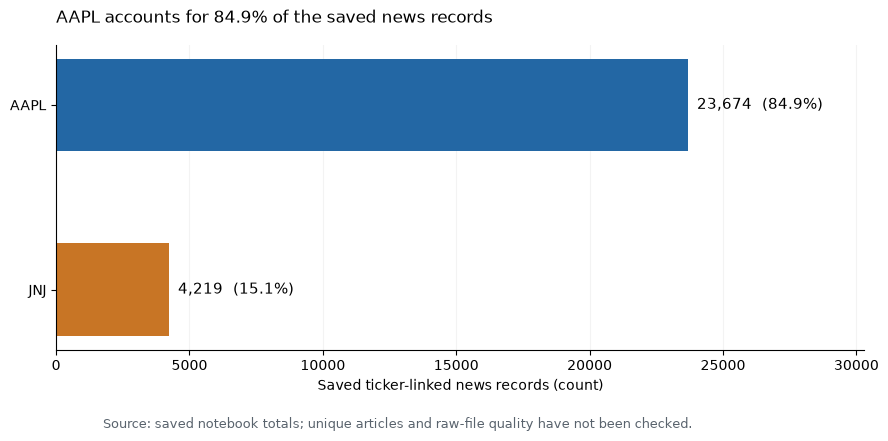

In [3]:
# Source: saved summary counts from the group's original notebook.
counts = saved["totals"]
total = int(counts["news_records"].sum())
share = float(counts.loc["AAPL", "share_pct"])
root = ROOT
fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.barh(counts.index[::-1], counts["news_records"].iloc[::-1],
               color=[COLORS[t] for t in counts.index[::-1]], height=0.5)
ax.set_xlim(0, counts["news_records"].max() * 1.28)
ax.set_xlabel("Saved ticker-linked news records (count)")
ax.set_title(f"AAPL accounts for {share:.1f}% of the saved news records", loc="left", pad=16)
for bar, ticker in zip(bars, counts.index[::-1]):
    value = int(counts.loc[ticker, "news_records"])
    pct = float(counts.loc[ticker, "share_pct"])
    ax.text(value + 350, bar.get_y() + bar.get_height() / 2,
            f"{value:,}  ({pct:.1f}%)", va="center", fontsize=11)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.text(0.12, 0.015, "Source: saved notebook totals; unique articles and raw-file quality have not been checked.",
         fontsize=9, color="#59636d")
fig.tight_layout(rect=(0, 0.06, 1, 1))
concentration = figures / "eda_saved_01_news_counts.png"
fig.savefig(concentration, dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)

## 3 News counts by year

The panels use different vertical scales. The 2026 sample ends in October, so its total cannot be compared directly with a full year. Annual totals can also hide missing days.


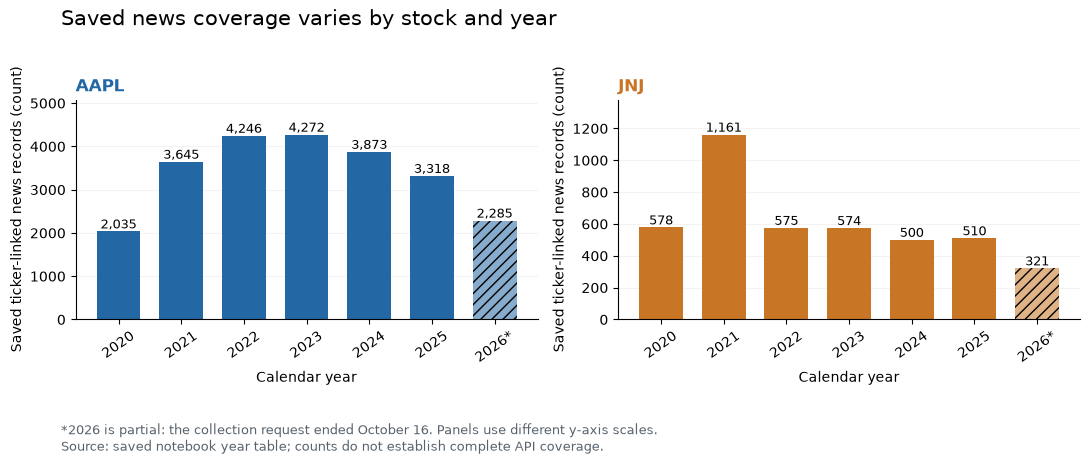

In [4]:
# Source: saved year-by-ticker counts; 2026 is partial.
pivot = tables["annual"].pivot(index="year", columns="ticker", values="news_records")
years = pivot.index.tolist()
x = np.arange(len(years))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
for ax, ticker in zip(axes, counts.index):
    bars = ax.bar(x, pivot[ticker], color=COLORS[ticker], width=0.7)
    bars[-1].set_hatch("///")
    bars[-1].set_alpha(0.55)
    ax.set_xticks(x, [str(y) if i < len(years) - 1 else f"{y}*" for i, y in enumerate(years)])
    ax.tick_params(axis="x", rotation=35)
    ax.set_title(ticker, loc="left", color=COLORS[ticker], fontweight="bold")
    ax.set_xlabel("Calendar year")
    ax.set_ylabel("Saved ticker-linked news records (count)")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.set_ylim(0, float(pivot[ticker].max()) * 1.19)
    for bar, value in zip(bars, pivot[ticker]):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{int(value):,}",
                ha="center", va="bottom", fontsize=9)
fig.suptitle("Saved news coverage varies by stock and year", x=0.06, ha="left", fontsize=15)
fig.text(0.06, 0.02, "*2026 is partial: the collection request ended October 16. Panels use different y-axis scales.\n"
         "Source: saved notebook year table; counts do not establish complete API coverage.",
         fontsize=9, color="#59636d")
fig.tight_layout(rect=(0, 0.13, 1, 0.94))
annual_plot = figures / "eda_saved_02_news_by_year.png"
fig.savefig(annual_plot, dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)

## 4 Additional data for EDA

- **Yahoo prices:** AAPL, AMZN, JNJ and SPY, January 2020–October 15, 2026.
- **EODHD demo headlines:** AAPL and AMZN, calendar year 2024.

AMZN was included because the demo supports it. This is an additional sample for review; the team still needs to choose the final stocks and source. Yahoo uses an undocumented public interface. Check provider terms before redistributing the data.


In [5]:
report = evaluation.get("report", evaluation)
print("Evaluation status:", report["status"])
if "price_quality" in evaluation:
    display(evaluation["price_quality"])
    display(pd.DataFrame(report["return_summary"]).round(3))
if "price_schema" in report:
    display(pd.DataFrame(report["price_schema"]))

Evaluation status: descriptive checks only; news archive completeness unverified


,symbol,rows,duplicate_date_rows,invalid_numeric_rows,invalid_ohlc_rows,non_session_rows,expected_sessions,usable_sessions,missing_or_excluded_sessions,first_observed_date,last_observed_date
0,AAPL,1706,0,0,0,0,1706,1706,0,2020-01-02,2026-10-15
1,AMZN,1706,0,0,0,0,1706,1706,0,2020-01-02,2026-10-15
2,JNJ,1706,0,0,0,0,1706,1706,0,2020-01-02,2026-10-15
3,SPY,1706,0,0,0,0,1706,1706,0,2020-01-02,2026-10-15


,symbol,return_observations,mean_daily_return_pct,daily_return_std_pct,min_daily_return_pct,max_daily_return_pct,up_day_pct
0,AAPL,1705,0.110,1.965,-12.865,15.329,53.196
1,AMZN,1705,0.083,2.240,-14.049,15.321,51.730
2,JNJ,1705,0.051,1.250,-7.592,7.998,51.730
3,SPY,1705,0.064,1.260,-10.942,10.502,54.663


,column,dtype,missing_rows
0,symbol,string,0
1,date,datetime64[ns],0
2,timestamp,"datetime64[ns, UTC]",0
3,open,float64,0
4,high,float64,0
5,low,float64,0
6,close,float64,0
7,volume,Int64,0
8,adjusted_close,float64,0


## 5 Price data checks

All four Yahoo series have 1,706 usable rows. The duplicate-date, missing-session, numeric and OHLC checks passed for this retrieval.

Returns and labels use adjusted close; OHLC checks use Yahoo's supplied columns. Missing sessions remain empty so a multi-session change cannot become a one-day return.


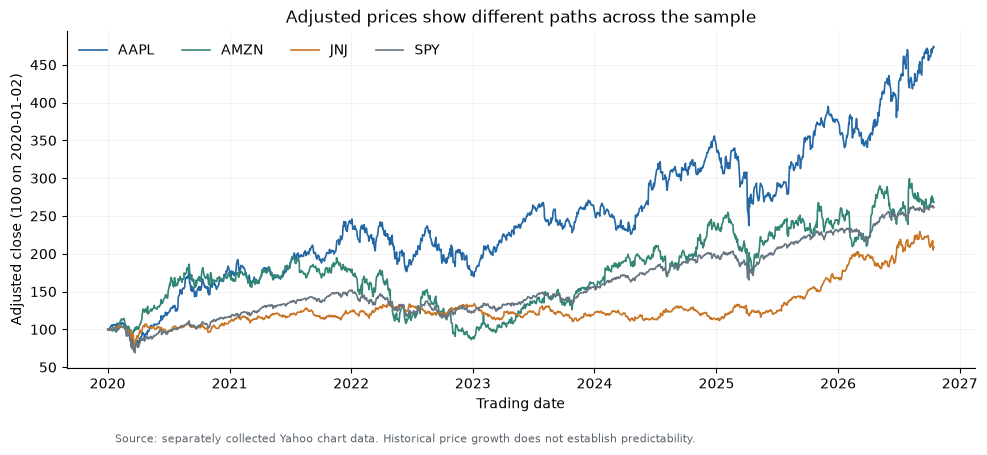

In [6]:
# Validate rows and align them to the NYSE calendar before plotting.
daily, price_quality, schedule = prepare_prices(prices_raw, "2020-01-01", "2026-10-16")
aligned = align_news(news_raw, schedule)
pivot = daily.pivot(index="date", columns="symbol", values="adjusted_close")
common = pivot.dropna(how="any")
if not common.empty:
    first = common.index[0]
    indexed = pivot.loc[first:].div(pivot.loc[first]).mul(100)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for symbol in indexed:
        ax.plot(indexed.index, indexed[symbol], label=symbol, color=COLORS.get(symbol), linewidth=1.2)
    ax.set(title="Adjusted prices show different paths across the sample", ylabel=f"Adjusted close (100 on {first.date()})", xlabel="Trading date")
    ax.grid(alpha=.15)
    ax.legend(ncol=len(indexed.columns), frameon=False)
    fig.text(.12, .005, "Source: separately collected Yahoo chart data. Historical price growth does not establish predictability.", fontsize=8, color="#59636d")
    fig.tight_layout(rect=(0, .04, 1, 1))
    save(fig, "01_indexed_prices")

Each series starts at 100 on the same date. A value of 150 means a 50% increase from its starting adjusted price.


## 6 Daily returns

`daily return (%) = 100 × (today's adjusted close / previous session's adjusted close − 1)`

The histograms share bins and scales. AMZN has the largest daily-return standard deviation (2.24%); JNJ has the smallest (1.25%). Extreme moves are retained for review.


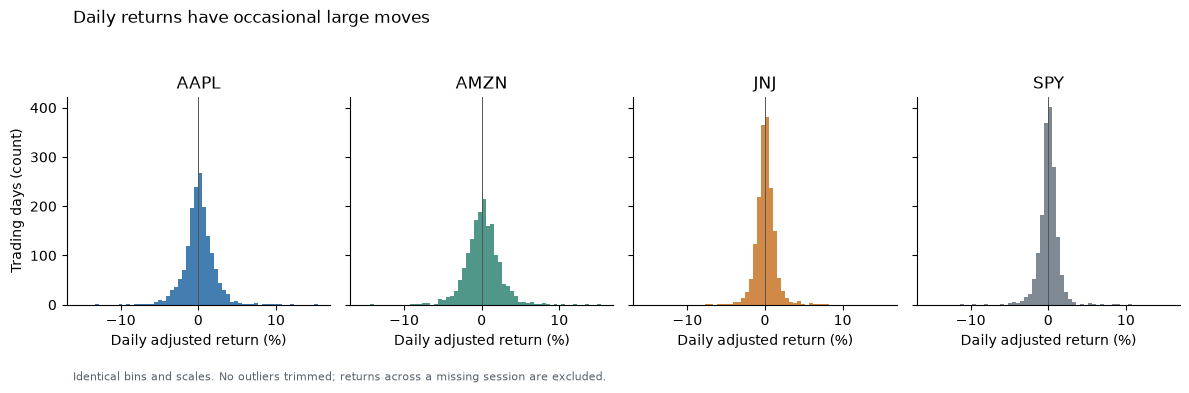

In [7]:
# Recompute returns explicitly; no filling across missing sessions.
daily["return_pct"] = daily.groupby("symbol")["adjusted_close"].transform(
    lambda values: values.pct_change(fill_method=None) * 100
)
summaries = []
fig, axes = plt.subplots(1, len(pivot.columns), figsize=(12, 3.8), sharex=True, sharey=True, squeeze=False)
all_returns = daily.return_pct.dropna()
max_abs = float(all_returns.abs().max()) if len(all_returns) else 1
bins = np.linspace(-max_abs - .1, max_abs + .1, 61)
for ax, symbol in zip(axes.flat, pivot.columns):
    group = daily.loc[daily.symbol.eq(symbol)]
    values = group.return_pct.dropna()
    ax.hist(values, bins=bins, color=COLORS.get(symbol), alpha=.85)
    ax.axvline(0, color="#555", lw=.7)
    ax.set(title=symbol, xlabel="Daily adjusted return (%)")
    summaries.append({"symbol": symbol, "return_observations": len(values), "mean_daily_return_pct": values.mean(),
                      "daily_return_std_pct": values.std(), "min_daily_return_pct": values.min(), "max_daily_return_pct": values.max(),
                      "up_day_pct": values.gt(0).mean() * 100})
axes[0, 0].set_ylabel("Trading days (count)")
fig.suptitle("Daily returns have occasional large moves", x=.065, ha="left")
fig.text(.065, .005, "Identical bins and scales. No outliers trimmed; returns across a missing session are excluded.", fontsize=8, color="#59636d")
fig.tight_layout(rect=(0, .05, 1, .93))
save(fig, "02_return_distributions")
report["return_summary"] = pd.DataFrame(summaries).round(5).to_dict("records")

## 7 Changes in volatility

Each line shows the standard deviation of returns over the latest 21 trading sessions. Higher values mean larger variation. Volatility changes over time, which matters when evaluating models on a later period; this plot does not identify the cause.


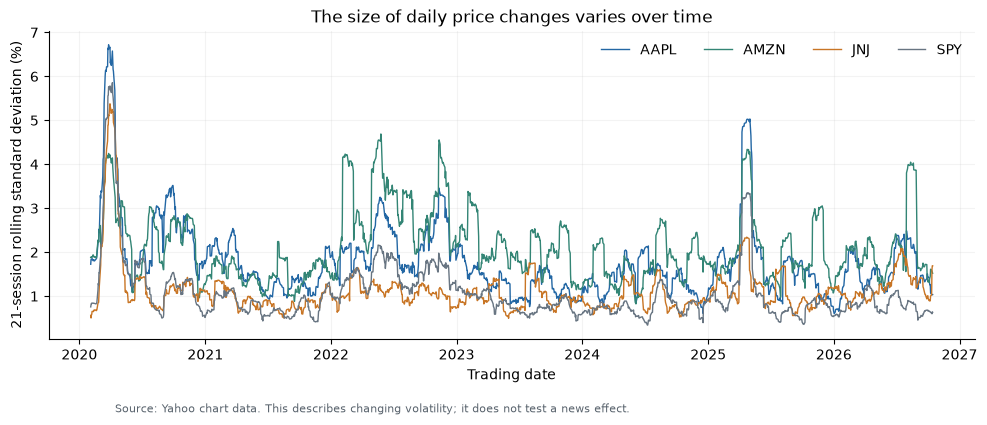

In [8]:
# Rolling standard deviation uses the previous 21 observed calendar sessions.
fig, ax = plt.subplots(figsize=(10, 4.2))
for symbol, group in daily.groupby("symbol"):
    ax.plot(group.date, group.return_pct.rolling(21, min_periods=21).std(), label=symbol, color=COLORS.get(symbol), lw=1)
ax.set(title="The size of daily price changes varies over time", xlabel="Trading date", ylabel="21-session rolling standard deviation (%)")
ax.grid(alpha=.15)
ax.legend(ncol=len(pivot.columns), frameon=False)
fig.text(.12, .005, "Source: Yahoo chart data. This describes changing volatility; it does not test a news effect.", fontsize=8, color="#59636d")
fig.tight_layout(rect=(0, .04, 1, 1))
save(fig, "03_rolling_volatility")

## 8 Target definition and class balance

One observation is one stock at a day's actual market close:

`y = 1` if the next trading day's adjusted close is higher than today's.

`y = 0` if it is lower or equal. A missing next-session price leaves the label missing.

Across the full 2020–2026 price sample, 53.2% of AAPL labels and 51.7% of AMZN/JNJ labels are up. The smaller 2024 paired sample has different shares: 56.8% for AAPL and 53.2% for AMZN.

Both models must use the same labels and dates. Outperforming SPY would be a separate label comparing returns over the same interval.


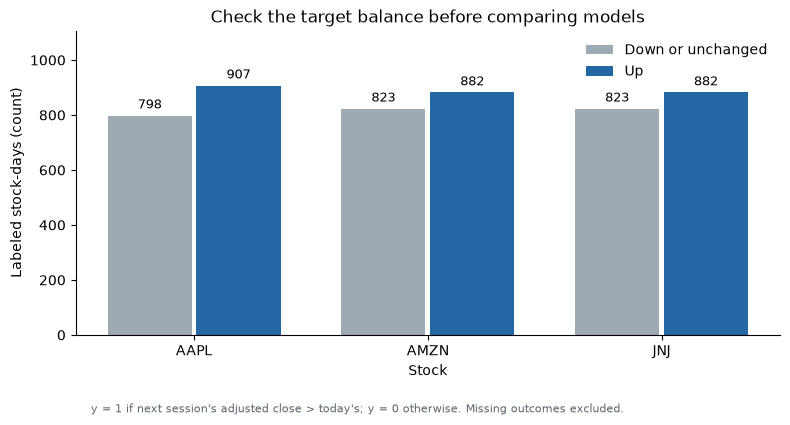

,symbol,down_or_unchanged,up,labeled_stock_days,up_pct
0,AAPL,798,907,1705,53.20
1,AMZN,823,882,1705,51.73
2,JNJ,823,882,1705,51.73


In [9]:
# One common next-trading-day target for both proposed models.
daily["next_return_pct"] = daily.groupby("symbol")["return_pct"].shift(-1)
daily["target_up"] = (
    daily["next_return_pct"].gt(0).astype("Int64")
    .where(daily["next_return_pct"].notna())
)
counts = []
for symbol in [s for s in pivot.columns if s != "SPY"]:
    target = daily.loc[daily.symbol.eq(symbol), "target_up"].dropna()
    counts.append({"symbol": symbol, "down_or_unchanged": int(target.eq(0).sum()), "up": int(target.eq(1).sum()),
                   "labeled_stock_days": len(target), "up_pct": float(target.mean() * 100) if len(target) else None})
report["target_balance"] = counts
labels = pd.DataFrame(counts).set_index("symbol")
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(labels))
for offset, name, color in [(-.19, "down_or_unchanged", "#9da9b3"), (.19, "up", "#2367a4")]:
    bars = ax.bar(x + offset, labels[name], width=.36, label=name.replace("_", " ").capitalize(), color=color)
    ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xticks(x, labels.index)
ax.set(title="Check the target balance before comparing models", ylabel="Labeled stock-days (count)", xlabel="Stock")
ax.set_ylim(0, labels[["down_or_unchanged", "up"]].max().max() * 1.22)
ax.legend(frameon=False)
fig.text(.12, .005, "y = 1 if next session's adjusted close > today's; y = 0 otherwise. Missing outcomes excluded.", fontsize=8, color="#59636d")
fig.tight_layout(rect=(0, .05, 1, 1))
save(fig, "04_target_balance")

display(pd.DataFrame(report["target_balance"]).round(2))

## 9 News data checks

The sample has 10,817 ticker-news records and 10,038 distinct URLs. After collection, no blank headlines or exact duplicates were found. Another 95 rows may be syndicated stories.

The company name or ticker appears in 42.7% of AAPL headlines and 32.6% of AMZN headlines. This is only a relevance check: unmatched stories may still matter. A spot-check found unrelated stories and an author/date line stored as a headline, so manual review is needed.

The November/December drop may reflect archive coverage. Also, 2,380 records (22.0%) are timestamped at midnight UTC and may have date-only precision. They remain in monthly totals but are excluded from daily pairing pending verification.

Median headline lengths are 11 words for AAPL and 10 for AMZN. Provider sentiment is kept as metadata; its historical availability is unverified.


,value
rows,10817
invalid_timestamps,0
blank_headlines,0
blank_links,0
suspected_exact_duplicate_rows,0
exact_duplicate_copies_excluded,0
midnight_utc_timestamp_rows,2380
same_headline_time_across_links_rows,95
unique_urls,10038
rows_with_company_named_in_headline,4057


,column,dtype,missing_rows
0,ticker,string,0
1,created_at,"datetime64[ns, UTC]",0
2,headline,string,0
3,link,string,0
4,source_domain,string,0
5,symbols,object,0
6,tags,object,0
7,sentiment_polarity,float64,1
8,sentiment_neg,float64,1
9,sentiment_neu,float64,1


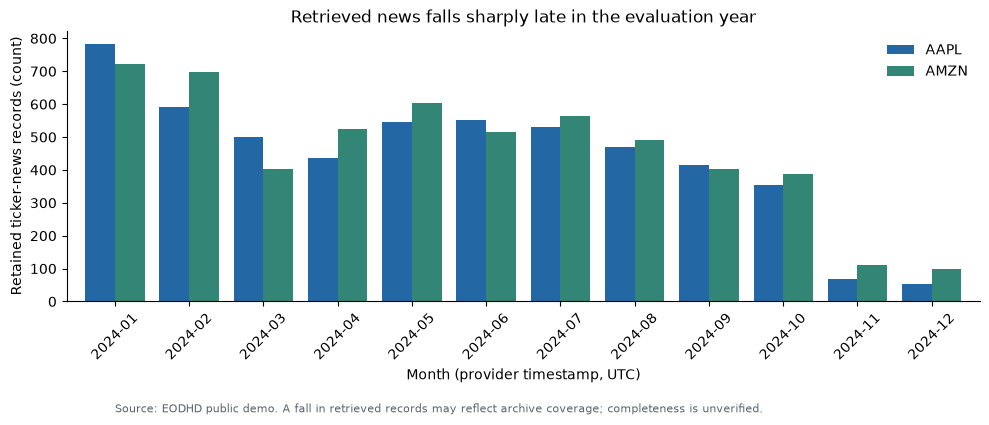

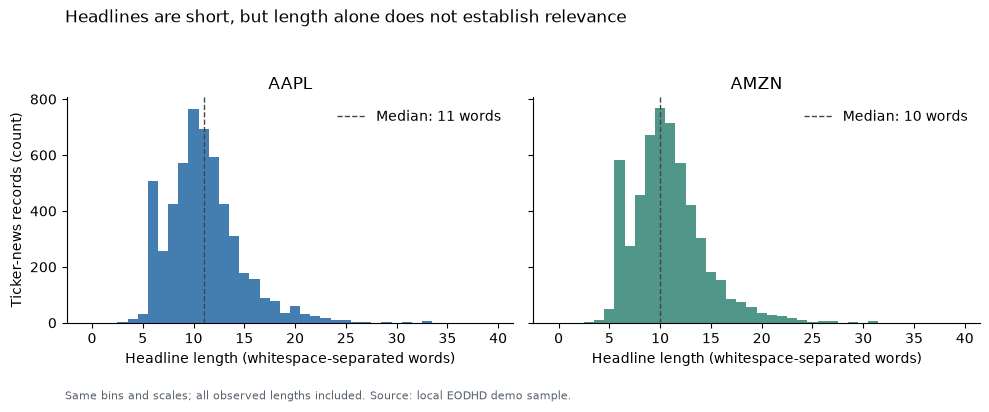

,ticker,records,median_words,p95_words,min_words,max_words
0,AAPL,5298,11.0,18.0,3,38
1,AMZN,5519,10.0,17.0,3,39


In [10]:
# Actual EODHD rows, excluding blank headlines and extra exact copies.
usable = aligned.loc[
    aligned.created_at.notna()
    & ~aligned.blank_headline
    & ~aligned.exclude_duplicate_copy
].copy()
display(pd.DataFrame([report["news_quality"]]).T.rename(columns={0: "value"}))
display(pd.DataFrame(report["news_schema"]))

# Count records by provider timestamp month (UTC), then draw the bars.
periods = usable.created_at.dt.tz_localize(None).dt.to_period("M")
monthly = usable.groupby([usable.ticker, periods]).size().unstack(0, fill_value=0).sort_index()
report["monthly_news_counts"] = monthly.reset_index(names="month").assign(month=lambda d: d.month.astype(str)).to_dict("records")
report["news_source_counts"] = (usable.groupby(["ticker", "source_domain"], dropna=False).size().reset_index(name="records").to_dict("records") if "source_domain" in usable else [])
fig, ax = plt.subplots(figsize=(10, 4.2))
monthly.index = monthly.index.astype(str)
monthly.plot.bar(ax=ax, color=[COLORS.get(s) for s in monthly], width=.8)
ax.set(title="Retrieved news falls sharply late in the evaluation year", xlabel="Month (provider timestamp, UTC)", ylabel="Retained ticker-news records (count)")
ax.tick_params(axis="x", rotation=45)
ax.legend(title=None, frameon=False)
fig.text(.12, .005, "Source: EODHD public demo. A fall in retrieved records may reflect archive coverage; completeness is unverified.", fontsize=8, color="#59636d")
fig.tight_layout(rect=(0, .04, 1, 1))
save(fig, "05_monthly_news")

# Count headline words, then draw the distributions.
lengths = usable.assign(headline_words=usable.headline.str.split().str.len())
report["headline_word_counts"] = []
fig, axes = plt.subplots(1, lengths.ticker.nunique(), figsize=(10, 4), sharex=True, sharey=True, squeeze=False)
bins = np.arange(-.5, int(lengths.headline_words.max()) + 1.5, 1)
for ax, (ticker, group) in zip(axes.flat, lengths.groupby("ticker")):
    ax.hist(group.headline_words, bins=bins, color=COLORS.get(ticker), alpha=.85)
    median = float(group.headline_words.median())
    ax.axvline(median, color="#444", lw=1, linestyle="--", label=f"Median: {median:g} words")
    ax.set(title=ticker, xlabel="Headline length (whitespace-separated words)")
    ax.legend(frameon=False)
    report["headline_word_counts"].append({"ticker": ticker, "records": len(group), "median_words": median,
                                           "p95_words": float(group.headline_words.quantile(.95)),
                                           "min_words": int(group.headline_words.min()), "max_words": int(group.headline_words.max())})
axes[0, 0].set_ylabel("Ticker-news records (count)")
fig.suptitle("Headlines are short, but length alone does not establish relevance", x=.07, ha="left")
fig.text(.07, .005, "Same bins and scales; all observed lengths included. Source: local EODHD demo sample.", fontsize=8, color="#59636d")
fig.tight_layout(rect=(0, .05, 1, .93))
save(fig, "07_headline_lengths")

display(pd.DataFrame(report["headline_word_counts"]))

## 10 Pairing news with the next trading day

For each prediction date, we group news by provider publication time:

`previous NYSE close < publication time ≤ current NYSE close`

The NYSE calendar handles holidays and early closes. After excluding midnight records and boundary windows, we have 250 stock-days per ticker, or 500 total. These timestamps do not verify historical availability or whether headlines were later edited; archive completeness is also unverified.

Each point compares a day's news count with the next session's return. Correlations are near zero: 0.0079 for AAPL and −0.0403 for AMZN. Whether headline wording helps still requires a model comparison. The 10,817 headline records are not 10,817 prediction observations.


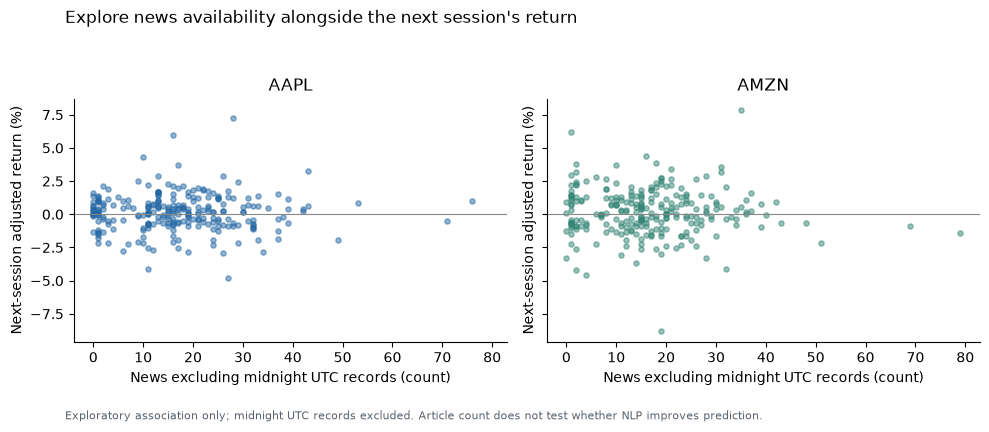

,ticker,paired_stock_days,pearson_news_count_next_return
0,AAPL,250,0.00791
1,AMZN,250,-0.04031


In [11]:
# News with potentially date-only timestamps stays out of cutoff pairing.
# Pair each close-window count with the next session's return, by ticker.
root = ROOT
news_summary = []
paired = []
for ticker, group in usable.groupby("ticker"):
    timed = group.loc[~group.midnight_utc_timestamp]
    if timed.empty:
        continue
    lo, hi = timed.created_at.min(), timed.created_at.max()
    eligible = schedule.index[(schedule.market_close.shift(1).ge(lo) & schedule.market_close.le(hi)).to_numpy()]
    n = timed.groupby("cutoff_date").size().reindex(eligible, fill_value=0)
    news_summary.append({"ticker": ticker, "records": len(group), "first_provider_time": lo.isoformat(),
                         "last_provider_time": hi.isoformat(), "interior_close_windows": len(n),
                         "midnight_utc_rows_excluded_from_pairing": int(group.midnight_utc_timestamp.sum()),
                         "windows_with_zero_retrieved_news": int(n.eq(0).sum()),
                         "mean_news_per_interior_window": round(float(n.mean()), 3) if len(n) else None,
                         "headline_company_name_pct": round(float(group.company_named_in_headline.mean() * 100), 2)})
    prices_for_ticker = daily.loc[daily.symbol.eq(ticker)].set_index("date")
    match = prices_for_ticker.join(n.rename("news_count"), how="inner")
    match["ticker"] = ticker
    paired.append(match.reset_index())
report["news_by_stock"] = news_summary
if paired:
    paired = pd.concat(paired, ignore_index=True)
    fig, axes = plt.subplots(1, len(news_summary), figsize=(10, 4.2), sharex=True, sharey=True, squeeze=False)
    correlations = []
    for ax, (ticker, group) in zip(axes.flat, paired.groupby("ticker")):
        available = group.dropna(subset=["news_count", "next_return_pct"])
        ax.scatter(available.news_count, available.next_return_pct, color=COLORS.get(ticker), s=14, alpha=.5)
        ax.axhline(0, color="#888", lw=.8)
        ax.set(title=ticker, xlabel="News excluding midnight UTC records (count)", ylabel="Next-session adjusted return (%)")
        correlations.append({"ticker": ticker, "paired_stock_days": len(available),
                             "pearson_news_count_next_return": round(float(available.news_count.corr(available.next_return_pct)), 5) if len(available)>2 else None})
    fig.suptitle("Explore news availability alongside the next session's return", x=.07, ha="left")
    fig.text(.07, .005, "Exploratory association only; midnight UTC records excluded. Article count does not test whether NLP improves prediction.", fontsize=8, color="#59636d")
    fig.tight_layout(rect=(0, .05, 1, .93))
    save(fig, "06_news_and_next_return")
    report["news_price_pairing"] = correlations
    processed = root / "data/processed/supplemental"
    processed.mkdir(parents=True, exist_ok=True)
    paired.to_parquet(processed / "paired_stock_days.parquet", index=False)

display(pd.DataFrame(report["news_price_pairing"]))

## 11 Original files still needed

The next cell checks for `data/raw/news/AAPL.parquet`, `data/raw/news/JNJ.parquet` and `data/raw/prices.parquet`. Their individual rows still need review.


In [12]:
# Show which original files are available. No API requests are made.
original_files = [ROOT / "data/raw/news/AAPL.parquet", ROOT / "data/raw/news/JNJ.parquet",
                  ROOT / "data/raw/prices.parquet"]
rows=[]
for path in original_files:
    row={"file":str(path.relative_to(ROOT)), "available":path.is_file()}
    if path.is_file():
        frame=pd.read_parquet(path)
        row.update(rows=len(frame), columns=", ".join(frame.columns))
    rows.append(row)
display(pd.DataFrame(rows))
if not all(path.is_file() for path in original_files):
    print("Original Alpaca files are still needed for checks on individual rows.")


,file,available
0,data/raw/news/AAPL.parquet,False
1,data/raw/news/JNJ.parquet,False
2,data/raw/prices.parquet,False


Original Alpaca files are still needed for checks on individual rows.


## 12 Next steps

Review news coverage, relevance and timestamps, then agree on the final stocks, dates and source. Compare market-only features with the same features plus headlines, using identical stock-days and chronological splits. Fit preprocessing and tune within the training period; keep the final test period untouched. No model comparison has been run yet.

### Sources

- [Group collection notebook](https://github.com/CarmenYan/finmedia-stock-pred/blob/main/src/collect_data.ipynb)
- [EODHD news API](https://eodhd.com/financial-apis/stock-market-financial-news-api)
- [EODHD terms](https://eodhd.com/financial-apis/terms-conditions)
- [NYSE calendar](https://pandas-market-calendars.readthedocs.io/en/latest/usage.html)
